# Class 6 – H1 Python pricer (Mia, jz4017)


In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# ----------------------------------------------------------------------
# Common parameters ("Pricing ATM")
# ----------------------------------------------------------------------
S0 = 100.0        # spot (= notional, so prices are in % of notional)
K = 100.0         # ATM strike
sigma = 0.16      # annual volatility
T = 1.0           # maturity in years
r = 0.0           # rate
DAYS_PER_YEAR = 256
SEED = 42

In [3]:
# ======================================================================
# Q1. Monte Carlo path generator (kept generic for future applications)
# ======================================================================
def generate_mc_paths(S0, sigma, T, n_paths, r=0.0,
                      steps_per_year=DAYS_PER_YEAR, seed=None):
    """
    Geometric Brownian Motion paths under the risk-neutral measure.

        S(t+dt) = S(t) * exp[(r - sigma^2/2) dt + sigma sqrt(dt) Z],  Z ~ N(0,1)

    Returns
        t     : array of times, shape (n_steps+1,)
        paths : array of prices, shape (n_paths, n_steps+1), paths[:, 0] = S0
    """
    rng = np.random.default_rng(seed)
    n_steps = max(1, int(round(T * steps_per_year)))
    dt = T / n_steps
    z = rng.standard_normal((n_paths, n_steps))
    log_increments = (r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * z
    log_paths = np.cumsum(log_increments, axis=1)
    paths = S0 * np.exp(np.hstack([np.zeros((n_paths, 1)), log_paths]))
    t = np.linspace(0.0, T, n_steps + 1)
    return t, paths


def plot_paths(ax, t, paths, title, n_show=50):
    """Plot a subset of paths plus the +/- 1 std envelope of the terminal distribution."""
    ax.plot(t, paths[:n_show].T, lw=0.7, alpha=0.6)
    ax.axhline(paths[0, 0], color="black", lw=0.8, ls="--")
    ax.set_title(title)
    ax.set_xlabel("time (years)")
    ax.set_ylabel("price")
    ax.grid(alpha=0.3)


def q1_graphs(n_paths=1000, n_show=50):
    # (a) same maturity, different volatilities
    vols = [0.08, 0.16, 0.32]
    fig, axes = plt.subplots(1, len(vols), figsize=(15, 4.5), sharey=True)
    for ax, v in zip(axes, vols):
        t, p = generate_mc_paths(S0, v, T, n_paths, r, seed=SEED)
        plot_paths(ax, t, p, f"σ = {v:.0%}, T = {T:.0f}Y   "
                             f"(terminal std = {p[:, -1].std():.1f})", n_show)
    fig.suptitle("Q1(a) - MC paths as a function of volatility")
    fig.tight_layout()
    fig.savefig("Q1a_paths_vs_vol.png", dpi=130)

    # (b) same volatility, different maturities
    mats = [0.25, 1.0, 4.0]
    fig, axes = plt.subplots(1, len(mats), figsize=(15, 4.5), sharey=True)
    for ax, m in zip(axes, mats):
        t, p = generate_mc_paths(S0, sigma, m, n_paths, r, seed=SEED)
        plot_paths(ax, t, p, f"σ = {sigma:.0%}, T = {m:g}Y   "
                             f"(terminal std = {p[:, -1].std():.1f})", n_show)
    fig.suptitle("Q1(b) - MC paths as a function of maturity")
    fig.tight_layout()
    fig.savefig("Q1b_paths_vs_maturity.png", dpi=130)

    # (c) terminal distributions: the spread scales with sigma*sqrt(T)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for v in vols:
        _, p = generate_mc_paths(S0, v, T, 20000, r, seed=SEED)
        axes[0].hist(p[:, -1], bins=80, density=True, alpha=0.5, label=f"σ={v:.0%}")
    axes[0].set_title(f"Terminal price distribution, T = {T:.0f}Y")
    axes[0].legend(); axes[0].grid(alpha=0.3)
    for m in mats:
        _, p = generate_mc_paths(S0, sigma, m, 20000, r, seed=SEED)
        axes[1].hist(p[:, -1], bins=80, density=True, alpha=0.5, label=f"T={m:g}Y")
    axes[1].set_title(f"Terminal price distribution, σ = {sigma:.0%}")
    axes[1].legend(); axes[1].grid(alpha=0.3)
    fig.suptitle("Q1(c) - spread of S(T) grows with σ√T")
    fig.tight_layout()
    fig.savefig("Q1c_terminal_distributions.png", dpi=130)
    plt.show()

In [4]:
# ======================================================================
# Q2. MC price of an ATM call using the paths of Q1
# ======================================================================
def mc_option_price(paths, K, T, r=0.0, kind="call"):
    """Discounted average payoff over the terminal values of the paths. Returns (price, std error)."""
    ST = paths[:, -1]
    payoff = np.maximum(ST - K, 0.0) if kind == "call" else np.maximum(K - ST, 0.0)
    disc = np.exp(-r * T)
    price = disc * payoff.mean()
    stderr = disc * payoff.std(ddof=1) / np.sqrt(len(payoff))
    return price, stderr

In [5]:
# ======================================================================
# Q3. Black-Scholes formula
# ======================================================================
def bs_price(S, K, sigma, T, r=0.0, kind="call"):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if kind == "call":
        return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

In [6]:
# ======================================================================
# Q4. Normal (Bachelier) formula
# ======================================================================
def normal_price(S, K, sigma, T, r=0.0, kind="call"):
    """
    Normal model: S(T) ~ N(F, (sigma*S)^2 T) with F = S e^{rT}, sigma quoted as a % of spot
    (so sigma*S is the absolute vol).  With r = 0 and K = S this gives
        price = S * sigma * sqrt(T) / sqrt(2*pi)  ~  0.4 * N * sigma * sqrt(T)
    which is the rule of thumb used in H2.
    """
    F = S * np.exp(r * T)
    v = sigma * S * np.sqrt(T)              # absolute std dev of S(T)
    d = (F - K) / v
    disc = np.exp(-r * T)
    if kind == "call":
        return disc * ((F - K) * norm.cdf(d) + v * norm.pdf(d))
    return disc * ((K - F) * norm.cdf(-d) + v * norm.pdf(d))

In [7]:
# ======================================================================
# Q5. Convergence of MC to Black-Scholes
# ======================================================================
def q5_convergence(path_counts, steps_per_year=16):
    # Only S(T) matters for a European payoff and, for GBM, its distribution is exact
    # whatever the number of time steps, so coarser steps are used here to keep memory low.
    bs_c = bs_price(S0, K, sigma, T, r, "call")
    bs_p = bs_price(S0, K, sigma, T, r, "put")
    rows = []
    for n in path_counts:
        _, p = generate_mc_paths(S0, sigma, T, n, r, steps_per_year=steps_per_year, seed=SEED)
        c, c_se = mc_option_price(p, K, T, r, "call")
        pu, p_se = mc_option_price(p, K, T, r, "put")
        rows.append((n, c, c_se, pu, p_se))

    print(f"\nQ5. Convergence of MC to BS  (BS call = {bs_c:.4f}, BS put = {bs_p:.4f})")
    print(f"{'paths':>10} {'MC call':>10} {'err':>8} {'MC put':>10} {'err':>8} {'std err':>8}")
    for n, c, c_se, pu, p_se in rows:
        print(f"{n:>10,d} {c:>10.4f} {c-bs_c:>+8.4f} {pu:>10.4f} {pu-bs_p:>+8.4f} {c_se:>8.4f}")

    ns = np.array([x[0] for x in rows])
    calls = np.array([x[1] for x in rows]); c_se = np.array([x[2] for x in rows])
    puts = np.array([x[3] for x in rows]);  p_se = np.array([x[4] for x in rows])

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].errorbar(ns, calls, yerr=1.96 * c_se, fmt="o-", capsize=3, label="MC call ± 95% CI")
    axes[0].axhline(bs_c, color="red", ls="--", label=f"BS call = {bs_c:.3f}")
    axes[0].set_xscale("log"); axes[0].set_title("ATM call"); axes[0].legend(); axes[0].grid(alpha=0.3)
    axes[1].errorbar(ns, puts, yerr=1.96 * p_se, fmt="o-", capsize=3, color="green", label="MC put ± 95% CI")
    axes[1].axhline(bs_p, color="red", ls="--", label=f"BS put = {bs_p:.3f}")
    axes[1].set_xscale("log"); axes[1].set_title("ATM put"); axes[1].legend(); axes[1].grid(alpha=0.3)
    for ax in axes:
        ax.set_xlabel("number of MC paths"); ax.set_ylabel("price (% of notional)")
    fig.suptitle("Q5 - MC prices converge to Black-Scholes as the number of paths grows (error ~ 1/√n)")
    fig.tight_layout()
    fig.savefig("Q5_mc_convergence.png", dpi=130)
    plt.show()

In [8]:
print("Parameters: S0 = K = 100 (ATM), sigma = 16%, T = 1Y, r = 0")

Parameters: S0 = K = 100 (ATM), sigma = 16%, T = 1Y, r = 0


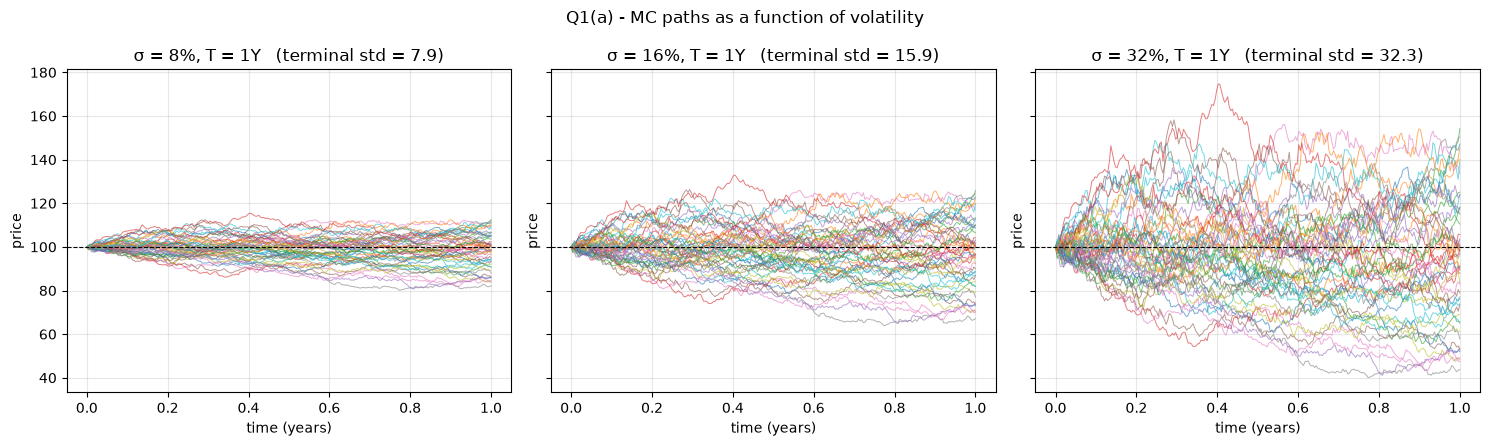

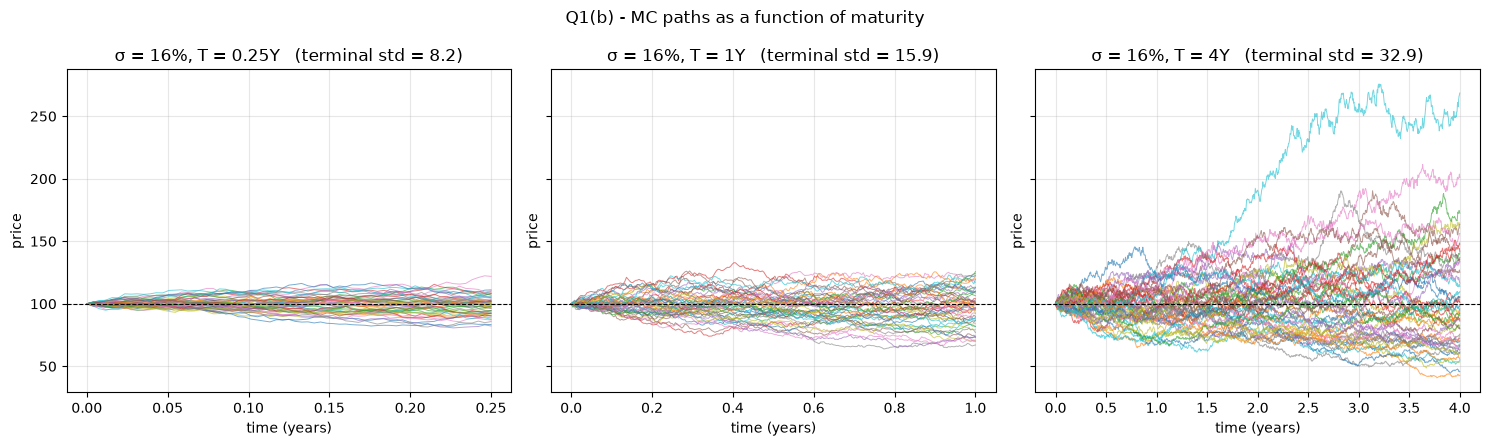

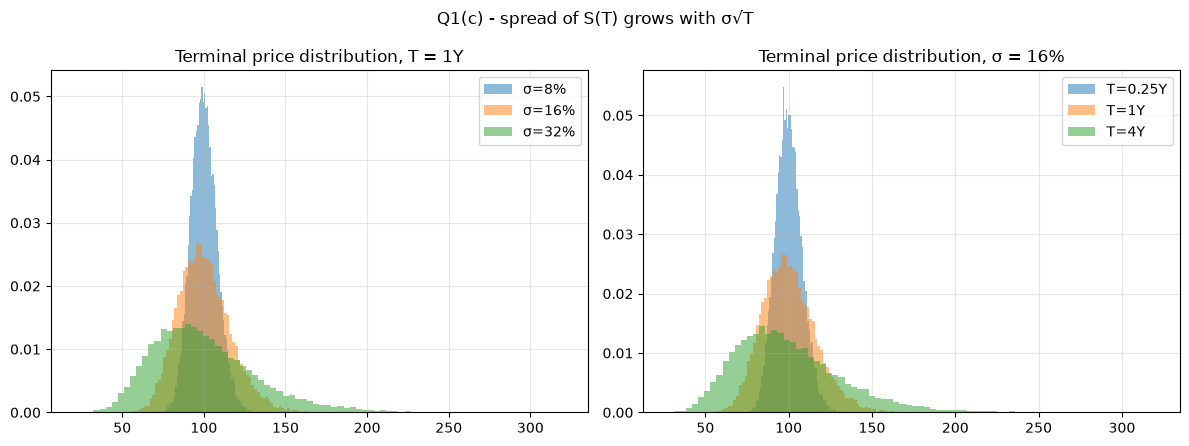


Q1. Saved Q1a_paths_vs_vol.png, Q1b_paths_vs_maturity.png, Q1c_terminal_distributions.png


In [9]:
# Q1
q1_graphs()
print("\nQ1. Saved Q1a_paths_vs_vol.png, Q1b_paths_vs_maturity.png, Q1c_terminal_distributions.png")

In [10]:
# Q2
t, paths = generate_mc_paths(S0, sigma, T, n_paths=10000, r=r, seed=SEED)
mc_call, se = mc_option_price(paths, K, T, r, "call")
print(f"\nQ2. MC ATM call price (10,000 paths) = {mc_call:.4f}  (std err {se:.4f})"
      f"  ->  on $100mm notional ≈ ${mc_call:.2f}mm")


Q2. MC ATM call price (10,000 paths) = 6.3493  (std err 0.1018)  ->  on $100mm notional ≈ $6.35mm


In [11]:
# Q3
print(f"\nQ3. Black-Scholes: call = {bs_price(S0, K, sigma, T, r, 'call'):.4f}, "
      f"put = {bs_price(S0, K, sigma, T, r, 'put'):.4f}")


Q3. Black-Scholes: call = 6.3763, put = 6.3763


In [12]:
# Q4
print(f"Q4. Normal formula: call = {normal_price(S0, K, sigma, T, r, 'call'):.4f}, "
      f"put = {normal_price(S0, K, sigma, T, r, 'put'):.4f}"
      f"   (rule of thumb 0.4·N·σ·√T = {0.4 * S0 * sigma * np.sqrt(T):.2f})")

Q4. Normal formula: call = 6.3831, put = 6.3831   (rule of thumb 0.4·N·σ·√T = 6.40)



Q5. Convergence of MC to BS  (BS call = 6.3763, BS put = 6.3763)
     paths    MC call      err     MC put      err  std err
       100     5.3498  -1.0264     7.5459  +1.1696   0.9683
     1,000     6.2155  -0.1608     6.7582  +0.3819   0.3335
    10,000     6.2949  -0.0813     6.4752  +0.0990   0.1028
   100,000     6.3830  +0.0067     6.3480  -0.0283   0.0325
 1,000,000     6.3665  -0.0097     6.3764  +0.0001   0.0103
 4,000,000     6.3804  +0.0041     6.3718  -0.0045   0.0051


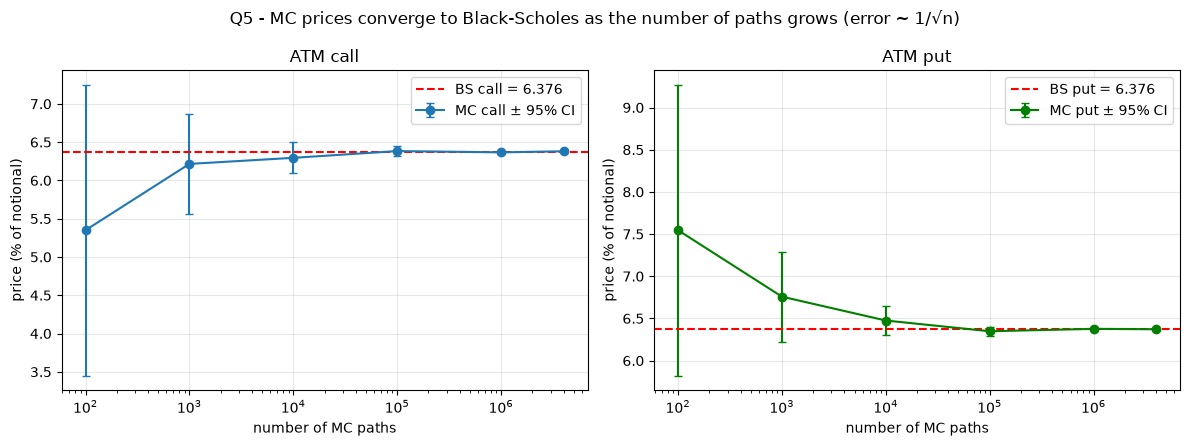

In [13]:
# Q5
q5_convergence([100, 1_000, 10_000, 100_000, 1_000_000, 4_000_000])